In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# PARAMETRI

In [2]:
EPOCHS = 50
BATCH_SIZE = 512
LEARNING_RATE = 1.0
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


TRAIN SET shape: torch.Size([60000, 28, 28])
TEST SET shape:  torch.Size([10000, 28, 28])


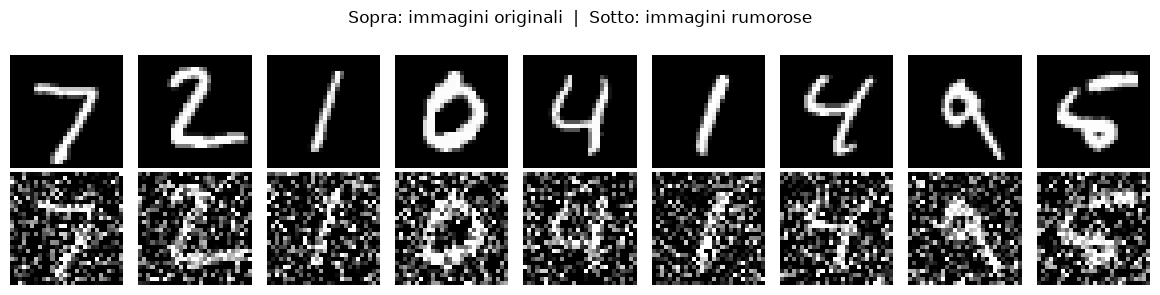

In [3]:
from datasets.datasets import load_MNIST
train_dataset, test_dataset, train_loader, test_loader = load_MNIST(batch_size=BATCH_SIZE, verbose=False)

print(f"TRAIN SET shape: {train_dataset.data.shape}")
print(f"TEST SET shape:  {test_dataset.data.shape}")

# Tutte le immagini in un unico tensore (N, 1, 28, 28) con valori in [0, 1], come quelle restituite da ToTensor
x_train = train_dataset.data.unsqueeze(1).float() / 255
x_test = test_dataset.data.unsqueeze(1).float() / 255

# RUMORE: gaussiano additivo, poi i valori vengono riportati in [0, 1]
NOISE_FACTOR = 0.5
generator = torch.Generator().manual_seed(0)
x_train_noisy = (x_train + NOISE_FACTOR * torch.randn(x_train.shape, generator=generator)).clamp(0, 1)
x_test_noisy = (x_test + NOISE_FACTOR * torch.randn(x_test.shape, generator=generator)).clamp(0, 1)

# Coppie (immagine rumorosa, immagine pulita) per il denoising autoencoder
noisy_train_loader = DataLoader(TensorDataset(x_train_noisy, x_train), batch_size=BATCH_SIZE, shuffle=True)
noisy_test_loader = DataLoader(TensorDataset(x_test_noisy, x_test), batch_size=BATCH_SIZE, shuffle=False)

n_show = 9
plt.figure(figsize=(1.3 * n_show, 3))
for i in range(n_show):
    plt.subplot(2, n_show, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.axis('off')
    plt.subplot(2, n_show, n_show + i + 1)
    plt.imshow(x_test_noisy[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle('Sopra: immagini originali  |  Sotto: immagini rumorose')
plt.tight_layout()
plt.show()

# MODELLO

In [4]:
#Parametri del modello
IN_CHANNELS = 1
FILTERS = 32
KERNEL_SIZE = 3

In [5]:
def conv_autoencoder():
    encoder = nn.Sequential(
        nn.Conv2d(IN_CHANNELS, FILTERS, KERNEL_SIZE, padding='same'), nn.ReLU(),    # (B, 1, 28, 28)  -> (B, 32, 28, 28)
        nn.MaxPool2d(kernel_size=2),                                                # (B, 32, 28, 28) -> (B, 32, 14, 14)
        nn.Conv2d(FILTERS, FILTERS, KERNEL_SIZE, padding='same'), nn.ReLU(),        # (B, 32, 14, 14) -> (B, 32, 14, 14)
    )
    decoder = nn.Sequential(
        nn.Upsample(scale_factor=2, mode='nearest'),                                # (B, 32, 14, 14) -> (B, 32, 28, 28)
        nn.Conv2d(FILTERS, IN_CHANNELS, KERNEL_SIZE, padding='same'), nn.Sigmoid(), # (B, 32, 28, 28) -> (B, 1, 28, 28)
    )
    return nn.Sequential(encoder, decoder).to(DEVICE)

# Stessa architettura per due modelli, che differiscono solo per i dati con cui vengono addestrati
autoencoder = conv_autoencoder()             # AE standard:  input pulito   -> target pulito
denoising_autoencoder = conv_autoencoder()   # Denoising AE: input rumoroso -> target pulito

# class ConvAutoEncoder(nn.Module):
#     def __init__(self, in_channels, filters, kernel_size):
#         super().__init__()
#         self.encoder = nn.Sequential(nn.Conv2d(in_channels, filters, kernel_size, padding='same'), nn.ReLU(),
#                                      nn.MaxPool2d(kernel_size=2),
#                                      nn.Conv2d(filters, filters, kernel_size, padding='same'), nn.ReLU())
#         self.decoder = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'),
#                                      nn.Conv2d(filters, in_channels, kernel_size, padding='same'), nn.Sigmoid())
#     def forward(self, x):
#         return self.decoder(self.encoder(x))
# autoencoder = ConvAutoEncoder(IN_CHANNELS, FILTERS, KERNEL_SIZE).to(DEVICE)
# denoising_autoencoder = ConvAutoEncoder(IN_CHANNELS, FILTERS, KERNEL_SIZE).to(DEVICE)

optimizer = torch.optim.Adadelta(autoencoder.parameters(), lr=LEARNING_RATE, rho=0.95, eps=1e-7)
denoising_optimizer = torch.optim.Adadelta(denoising_autoencoder.parameters(), lr=LEARNING_RATE, rho=0.95, eps=1e-7)
criterion = nn.BCELoss()

autoencoder

Sequential(
  (0): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
  )
  (1): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (2): Sigmoid()
  )
)

# ADDESTRAMENTO

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

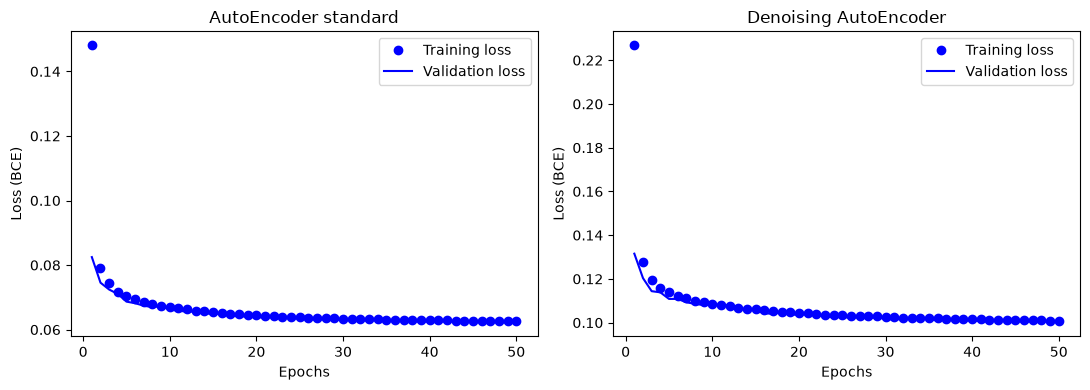

In [6]:
os.makedirs('histories', exist_ok=True)

def train_or_load(filename, model, optimizer, train_fn, train_loader, test_loader):
    hist_path = f'histories/{filename}.hist'
    weights_path = f'histories/{filename}.pt'
    if os.path.isfile(hist_path) and os.path.isfile(weights_path):
        with open(hist_path, 'rb') as hist_file:
            history_dict = pickle.load(hist_file)
        model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
    else:
        history_dict = train_fn(model, optimizer, criterion, train_loader, test_loader, EPOCHS, DEVICE)
        with open(hist_path, 'wb') as hist_file:
            pickle.dump(history_dict, hist_file)
        torch.save(model.state_dict(), weights_path)
    return history_dict

# AE standard: ricostruisce l'immagine che riceve (target = input)
history_ae = train_or_load("normal", autoencoder, optimizer,
                           utils.train_autoencoder, train_loader, test_loader)

# Denoising AE: riceve l'immagine rumorosa e deve restituire quella pulita (target diverso dall'input).
# Per questo si usa utils.train, che prende come target il secondo elemento di ogni coppia del loader
history_dae = train_or_load("denoising", denoising_autoencoder, denoising_optimizer,
                            utils.train_denoising_autoencoder, noisy_train_loader, noisy_test_loader)

plt.figure(figsize=(11, 4))
for i, (history_dict, title) in enumerate([(history_ae, 'AutoEncoder standard'),
                                           (history_dae, 'Denoising AutoEncoder')]):
    epochs = range(1, len(history_dict['loss']) + 1)
    plt.subplot(1, 2, i + 1)
    plt.plot(epochs, history_dict['loss'], 'bo', label='Training loss')
    plt.plot(epochs, history_dict['val_loss'], 'b', label='Validation loss')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Loss (BCE)')
    plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# VALUTAZIONE

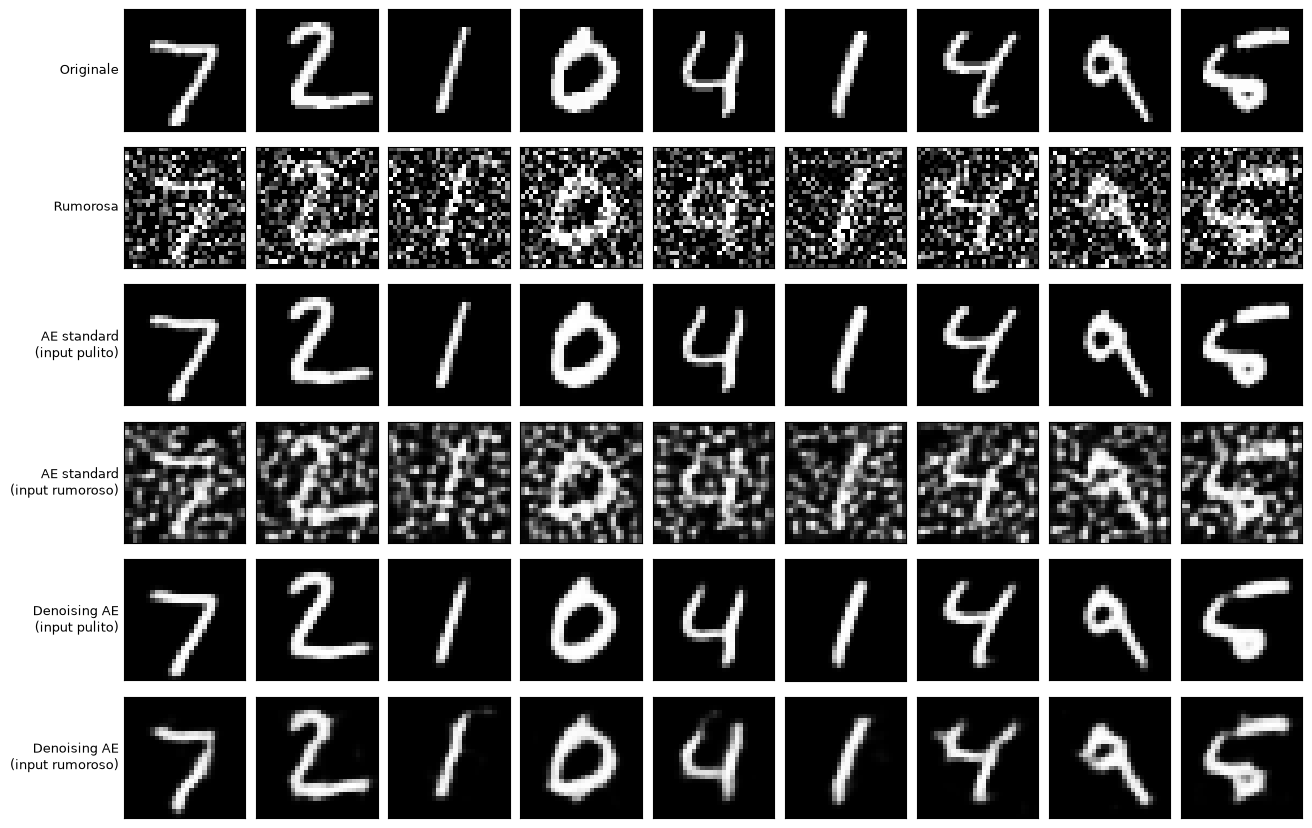

In [7]:
# TEST: ricostruzioni dei due autoencoder, a partire dalle immagini pulite e da quelle rumorose
n_show = 9
x, x_noisy = x_test[:n_show], x_test_noisy[:n_show]
autoencoder.eval()
denoising_autoencoder.eval()
with torch.no_grad():
    rows = [
        ('Originale', x),
        ('Rumorosa', x_noisy),
        ('AE standard\n(input pulito)', autoencoder(x.to(DEVICE)).cpu()),
        ('AE standard\n(input rumoroso)', autoencoder(x_noisy.to(DEVICE)).cpu()),
        ('Denoising AE\n(input pulito)', denoising_autoencoder(x.to(DEVICE)).cpu()),
        ('Denoising AE\n(input rumoroso)', denoising_autoencoder(x_noisy.to(DEVICE)).cpu()),
    ]

plt.figure(figsize=(1.3 * n_show + 1.5, 1.4 * len(rows)))
for r, (title, images) in enumerate(rows):
    for i in range(n_show):
        plt.subplot(len(rows), n_show, r * n_show + i + 1)
        plt.imshow(images[i].squeeze(), cmap='gray')
        plt.xticks([])
        plt.yticks([])
        if i == 0:
            plt.ylabel(title, rotation=0, ha='right', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
# ERRORE rispetto alle immagini pulite: MSE medio su tutto il test set
def mean_error(model, x_in, x_target, batch_size=1024):
    model.eval()
    errors = []
    with torch.no_grad():
        for i in range(0, len(x_in), batch_size):
            x_rec = model(x_in[i:i + batch_size].to(DEVICE)).cpu()
            errors.append(((x_rec - x_target[i:i + batch_size]) ** 2).flatten(1).mean(dim=1))
    return torch.cat(errors).mean().item()

print(f"{'MSE rispetto alle immagini pulite':<34}{'Test pulito':>13}{'Test rumoroso':>15}")
print(f"{'Nessun modello (input stesso)':<34}{0:>13.4f}{((x_test_noisy - x_test) ** 2).mean().item():>15.4f}")
for name, model in [('AutoEncoder standard', autoencoder), ('Denoising AutoEncoder', denoising_autoencoder)]:
    print(f"{name:<34}{mean_error(model, x_test, x_test):>13.4f}{mean_error(model, x_test_noisy, x_test):>15.4f}")

MSE rispetto alle immagini pulite   Test pulito  Test rumoroso
Nessun modello (input stesso)            0.0000         0.1156
AutoEncoder standard                     0.0008         0.0870
Denoising AutoEncoder                    0.0036         0.0120
